# <span style="color:green"> Numerical Simulation Laboratory </span>
## <span style="color:brown"> Python Exercise 12 </span>
## <span style="color:orange"> Keras - Deep & Convolutional Neural Network image recognition </span>

### MNIST with Keras

The goal of exercise 12 is to use deep neural network models, implemented in the Keras python package, to recognize and distinguish between the ten handwritten digits (0-9).

The MNIST dataset comprises $70000$ handwritten digits, each of which comes in a square image, divided into a $28\times 28$ pixel grid. Every pixel can take on $256$ gradation of the gray color, interpolating between white and black, and hence each data point assumes any value in the set $\{0,1,\dots,255\}$. Since there are $10$ categories in the problem, corresponding to the ten digits, this problem represents a generic **classification task**. 

In [1]:
import tensorflow as tf
from tensorflow import keras
import os
import numpy as np
import matplotlib.pyplot as plt
seed=0
np.random.seed(seed) # fix random seed
tf.random.set_seed(seed)

2026-10-13 13:10:42.764170: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


#### Step 1: Load and Process the Data

Keras can conveniently download the MNIST data from the web. All we need to do is import the `mnist` module and use the `load_data()` class, and it will create the training and test data sets or us.

The MNIST set has pre-defined test and training sets, in order to facilitate the comparison of the performance of different models on the data.

Once we have loaded the data, we need to format it in the correct shape.

In [2]:
from keras.datasets import mnist

# input image dimensions
img_rows, img_cols = 28, 28 # number of pixels 
# output
num_classes = 10 # 10 digits

# the data, split between train and test sets
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

X_train shape: (60000, 28, 28)
Y_train shape: (60000,)


#### Example: to_categorical

Converts a class vector (integers) to binary class matrix. E.g. for use with categorical_crossentropy.

In [3]:
# Consider an array of 5 labels out of a set of 3 classes {0, 1, 2}:
labels = np.array([0, 2, 1, 2, 0])
# `to_categorical` converts this into a matrix with as many columns as there are classes.
# The number of rows stays the same.
keras.utils.to_categorical(labels)

array([[1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

#### Reshape data and convert labels to be used with categorical cross entropy

X_train shape: (60000, 784)
X_test shape: (10000, 784)

an example of a data point with label 4


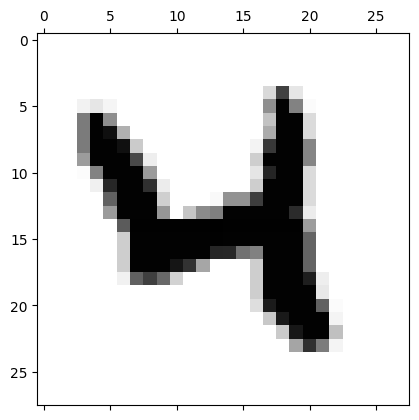

... and with label [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.] after to_categorical

X_train shape: (60000, 784)
Y_train shape: (60000, 10)


In [4]:
# reshape data, it could depend on Keras backend
X_train = X_train.reshape(X_train.shape[0], img_rows*img_cols)
X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print()

# cast to floats
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# rescale data in interval [0,1]
X_train /= 255
X_test /= 255

# look at an example of data point
print('an example of a data point with label', Y_train[20])
# matshow: display a matrix in a new figure window
plt.matshow(X_train[20,:].reshape(28,28),cmap='binary')
plt.show()

# convert class vectors to binary class matrices, e.g. for use with categorical_crossentropy
Y_train = keras.utils.to_categorical(Y_train, num_classes)
Y_test = keras.utils.to_categorical(Y_test, num_classes)
print('... and with label', Y_train[20], 'after to_categorical')
print()
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

#### Step 2: Define the Neural Net and its Architecture

We can now move on to construct our deep neural net. We shall use Keras's `Sequential()` class to instantiate a model, and will add different deep layers one by one using the `add()` method

For the purposes of our example, it suffices to focus on `Dense` layers for simplicity. Every `Dense()` layer accepts as its first required argument an integer which specifies the number of neurons. The type of activation function for the layer is defined using the `activation` optional argument, the input of which is the name of the activation function in `string` format. Examples include `relu`, `tanh`, `elu`, `sigmoid`, `softmax`. 

In order for our DNN to work properly, we have to make sure that the numbers of input and output neurons for each layer match. Therefore, we specify the shape of the input in the first layer of the model explicitly using the optional argument `input_shape=(N_features,)`. The sequential construction of the model then allows Keras to infer the correct input/output dimensions of all hidden layers automatically. Hence, we only need to specify the size of the softmax output layer to match the number of categories.

In [5]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input

def create_DNN():
    # instantiate model
    model = Sequential()
    model.add(Input(shape=(img_rows*img_cols,)))
    # add a dense all-to-all relu layer
    model.add(Dense(400, activation='relu'))
    # add a dense all-to-all relu layer
    model.add(Dense(100, activation='relu'))
    # apply dropout with rate 0.5
    model.add(Dropout(0.5))
    # soft-max layer
    model.add(Dense(num_classes, activation='softmax'))
    
    return model

print('Model architecture created successfully!')

Model architecture created successfully!


#### Step 3: Choose the Optimizer and the Cost Function

Next, we choose the loss function according to which to train the DNN. For classification problems, this is the cross entropy, and since the output data was cast in categorical form, we choose the `categorical_crossentropy` defined in Keras' `losses` module. Depending on the problem of interest one can pick any other suitable loss function. To optimize the weights of the net, we choose SGD. This algorithm is already available to use under Keras' `optimizers` module, but we could use any other built-in one as well. The parameters for the optimizer, such as `lr` (learning rate) or `momentum` are passed using the corresponding optional arguments of the `SGD()` function. All available arguments can be found in Keras' online documentation at [https://keras.io/](https://keras.io/). While the loss function and the optimizer are essential for the training procedure, to test the performance of the model one may want to look at a particular `metric` of performance. For instance, in categorical tasks one typically looks at their `accuracy`, which is defined as the percentage of correctly classified data points. To complete the definition of our model, we use the `compile()` method, with optional arguments for the `optimizer`, `loss`, and the validation `metric` as follows:

In [6]:
from keras.optimizers import SGD, Adam, RMSprop, Adagrad, Adadelta, Adam, Adamax, Nadam

def compile_model():
    # create the model
    model=create_DNN()
    # compile the model
    model.compile(loss=keras.losses.categorical_crossentropy,
                  optimizer=SGD(),
                  metrics=['acc'])
    return model

print('Model compiled successfully and ready to be trained.')

Model compiled successfully and ready to be trained.


#### Step 4: Train the model

We train our DNN in minibatches. 

Shuffling the training data during training improves stability of the model. Thus, we train over a number of training epochs. Each epoch corresponds to using **all the train data** divided in minibatches.

Training the DNN is a one-liner using the `fit()` method of the `Sequential` class. The first two required arguments are the training input and output data. As optional arguments, we specify the mini-`batch_size`, the number of training `epochs`, and the test or `validation_data`. To monitor the training procedure for every epoch, we set `verbose=True`. 

In [7]:
# training parameters
batch_size = 32
epochs = 5

# create the deep neural net
model_DNN = compile_model()

# train DNN and store training info in history
history = model_DNN.fit(X_train, Y_train,
          batch_size=batch_size,
          epochs=epochs,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          verbose=1,
          validation_data=(X_test, Y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - acc: 0.7672 - loss: 0.7916 - val_acc: 0.9104 - val_loss: 0.3261
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - acc: 0.8868 - loss: 0.3962 - val_acc: 0.9285 - val_loss: 0.2494
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - acc: 0.9100 - loss: 0.3188 - val_acc: 0.9394 - val_loss: 0.2061
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - acc: 0.9229 - loss: 0.2741 - val_acc: 0.9471 - val_loss: 0.1785
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - acc: 0.9315 - loss: 0.2418 - val_acc: 0.9532 - val_loss: 0.1601


#### Step 5: Evaluate the Model Performance on the *Unseen* Test Data

Next, we evaluate the model and read of the loss on the test data, and its accuracy using the `evaluate()` method.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.9532 - loss: 0.1601

Test loss: 0.1601308435201645
Test accuracy: 0.9531999826431274


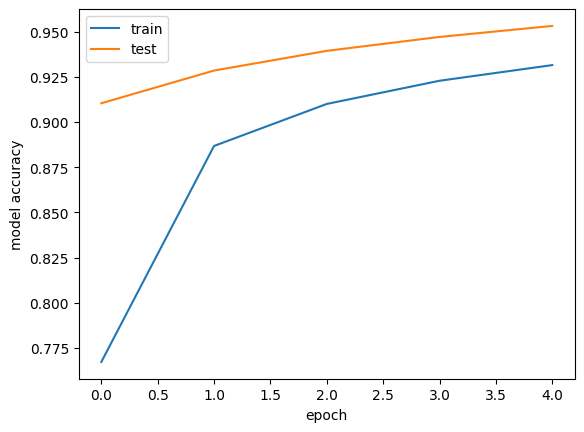

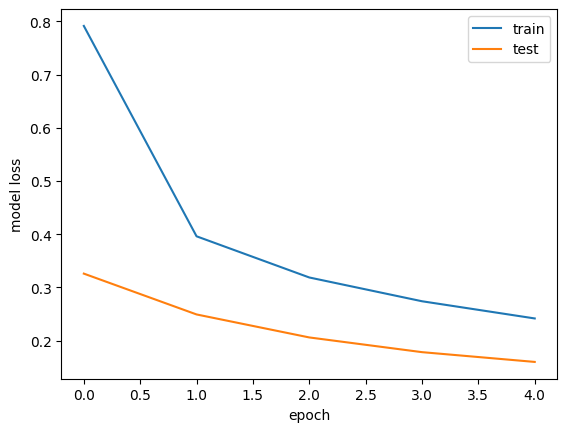

In [8]:
# evaluate model
score = model_DNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

# look into training history

# summarize history for accuracy
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.ylabel('model accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.ylabel('model loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='best')
plt.show()

Dropout, during training, slices off some artificial neurons, thus, training accuracy suffers.

Dropout, during testing, turns itself off and allows all of the ‘weak classifiers’ in the neural network to be used. Thus, testing accuracy improves with respect to training accuracy.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


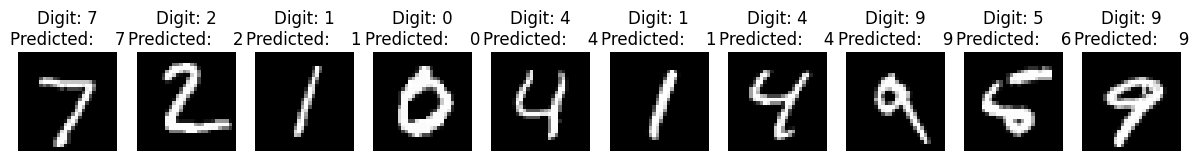

In [9]:
#X_test = X_test.reshape(X_test.shape[0], img_rows*img_cols)
predictions = model_DNN.predict(X_test)

X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols,1)

plt.figure(figsize=(15, 15)) 
for i in range(10):    
    ax = plt.subplot(2, 10, i + 1)    
    plt.imshow(X_test[i, :, :, 0], cmap='gray')    
    plt.title("Digit: {}\nPredicted:    {}".format(np.argmax(Y_test[i]), np.argmax(predictions[i])))    
    plt.axis('off') 
plt.show()

### Exercise 12.1

<span style="color:red">Change at will and train your DNN by increasing the number of epochs to an adeuqate value</span>. Try to use at least two other optimizers, different from SGD: <span style="color:red">watch to accuracy and loss for training and validation data and comment on the performances</span>.

### <span style="color:green"> RESULTS: </span>

The deep neural network defined above was trained for only 5 epochs with SGD. In this exercise we trained it for 20 epochs with four different optimizers, keeping everything else fixed.

The four optimizers we used are:

<small><code>sgd</code></small>: a plain stochastic gradient descent, with a fixed learning rate $0.01$;

<small><code>adam</code></small> and <small><code>rmsprop</code></small>: they adapt the step of each weight using the history of its gradients, with a learning rate of $0.001$;

<small><code>adagrad</code></small>: it also adapts the step, but divides it by the sum of all past squared gradients, so the step can only decrease during the training and it has a learning rate of $0.001$.

All optimizers are used with the default Keras settings. For each one we studied the accuracy, which is the fraction of correctly classified images, and the loss on the training and test data as a function of the epoch. The table below reports, for each optimizer, the final train and test accuracy, the final test loss, and the "best epoch" which is the epoch where the test loss reaches its minimum.


In [10]:
C_BLUE, C_GREEN = "#0c459a", "#109e28"
colors = ["#0c459a", "#2b8fd6", "#13a89e", "#109e28"]

X_train_flat = X_train.reshape(X_train.shape[0], img_rows*img_cols)
X_test_flat  = X_test.reshape(X_test.shape[0], img_rows*img_cols)

optimizer_names = ['sgd', 'adam', 'rmsprop', 'adagrad']
N_epochs = 20

histories = {}
models = {}
for opt in optimizer_names:
    tf.random.set_seed(seed)
    model = create_DNN()
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['acc'])
    print(f'Training with {opt} ...')
    h = model.fit(X_train_flat, Y_train, batch_size=32, epochs=N_epochs, shuffle=True,
                  validation_data=(X_test_flat, Y_test), verbose=0)
    histories[opt] = h.history
    models[opt] = model

# summary table
print(f"\n{'optimizer':>9} {'train acc':>10} {'test acc':>9} {'test loss':>10} {'best epoch':>11}")
for opt, h in histories.items():
    best_epoch = np.argmin(h['val_loss']) + 1      # epoch with the smallest test loss
    print(f"{opt:>9} {h['acc'][-1]:>10.4f} {h['val_acc'][-1]:>9.4f} {h['val_loss'][-1]:>10.4f} {best_epoch:>11}")

Training with sgd ...
Training with adam ...
Training with rmsprop ...
Training with adagrad ...

optimizer  train acc  test acc  test loss  best epoch
      sgd     0.9760    0.9776     0.0737          20
     adam     0.9944    0.9801     0.1196           5
  rmsprop     0.9825    0.9758     0.2271           2
  adagrad     0.9203    0.9412     0.2029          20


We then plotted the accuracy and the loss as a function of the epoch, for the training and test data, for each optimizer:

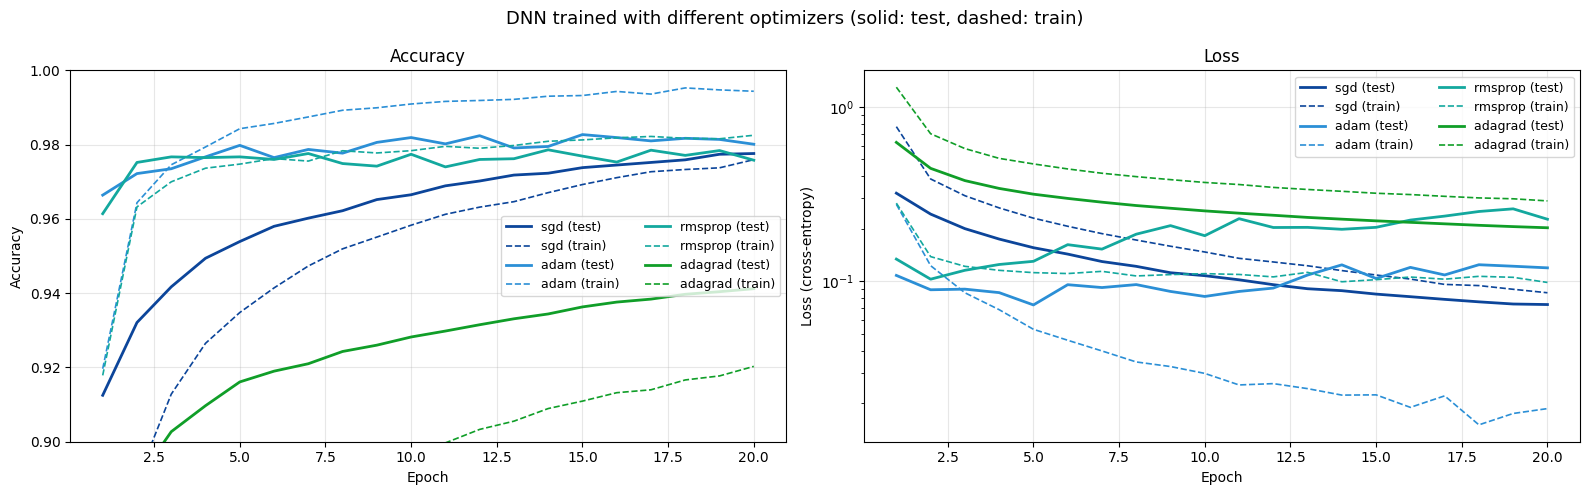

In [11]:
epochs = np.arange(1, N_epochs + 1)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for opt, col in zip(optimizer_names, colors):
    h = histories[opt]
    axs[0].plot(epochs, h['val_acc'], color=col, lw=2, label=f'{opt} (test)')
    axs[0].plot(epochs, h['acc'],     color=col, lw=1.2, ls='--', label=f'{opt} (train)')
    axs[1].plot(epochs, h['val_loss'], color=col, lw=2, label=f'{opt} (test)')
    axs[1].plot(epochs, h['loss'],     color=col, lw=1.2, ls='--', label=f'{opt} (train)')

axs[0].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy', ylim=(0.9, 1.0))
axs[1].set(xlabel='Epoch', ylabel='Loss (cross-entropy)', title='Loss', yscale='log')
for ax in axs:
    ax.legend(ncol=2, fontsize=9)
    ax.grid(True, alpha=0.3)
fig.suptitle('DNN trained with different optimizers (solid: test, dashed: train)', fontsize=13)
plt.tight_layout()
plt.show()

From the two plots we see that SGD improves slowly but steadily, after 20 epochs its test accuracy is about 97.5% and its test loss is still decreasing, so more epochs would probably improve the network further.

On the other hand, Adam and RMSprop are the fastest in terms of accuracy and reach about 98% after a few epochs. However, their test loss reaches a minimum early and then starts to grow, while the training loss keeps decreasing. This means that the network is becoming too confident on the training images and starts to overfit. The effect is strongest for RMSprop, whose test loss is minimum already at the second epoch and then grows with large fluctuations. For Adam the increase is much smaller but still present. In both cases it would be better to stop the training around the minimum of the test loss perfortming in this way an early stopping.

Adagrad is the slowest of the four, because its step keeps shrinking, and after 20 epochs it is still clearly behind the others.

For SGD and Adagrad the training accuracy is lower than the test accuracy. This happens because the training accuracy is averaged over each epoch while the network is still improving, and the test accuracy is measured at the end of the epoch.

We chose Adam because it gives the best compromise between speed and accuracy, but only for a small number of epochs: after the minimum of the test loss the network starts to overfit. We also used it for the CNN, where the dropout layer helps to reduce this effect.

In [12]:
model_DNN = models['adam']      # DNN used for the comparison with the CNN

#### Creating Convolutional Neural Nets with Keras

We have so far considered each MNIST data sample as a $(28\times 28,)$-long 1d vector. On the other hand, we do know that in every one of the hand-written digits there are *local* spatial correlations between the pixels, but also *translational invariance*, which we would like to take advantage of to improve the accuracy of our classification model. To this end, we first need to reshape the training and test input data as follows

In [13]:
# you will need the following for Convolutional Neural Networks
from keras.layers import Flatten, Conv2D, MaxPooling2D

# reshape data, depending on Keras backend
if keras.backend.image_data_format() == 'channels_first':
    X_train = X_train.reshape(X_train.shape[0], 1, img_rows, img_cols)
    X_test = X_test.reshape(X_test.shape[0], 1, img_rows, img_cols)
    input_shape = (1, img_rows, img_cols)
else:
    X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
    X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)
    input_shape = (img_rows, img_cols, 1)
    
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)
print()
print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')

X_train shape: (60000, 28, 28, 1)
Y_train shape: (60000, 10)

60000 train samples
10000 test samples


One can ask the question of whether a neural net can learn to recognize such local patterns. This can be achieved by using convolutional layers.

### Exercise 12.2

Change the architecture of your DNN using convolutional layers. Use `Conv2D`, `MaxPooling2D`, `Dropout`, but also do not forget `Flatten`, a standard `Dense` layer and `soft-max` in the end. I have merged step 2 and 3 in the following definition of `create_CNN()` that **<span style="color:red">you should complete</span>**:

### <span style="color:green"> RESULTS: </span>

A dense network treats a $28\times28$ image as a list of 784 independent numbers so it does not know which pixels are close to each other. A convolutional network instead looks at small patches of the image and uses the same filters at every position. We implemented the convolutional neural network following the example given in class.

The following table summarises the architecture of the network:

The first layer is a Conv2D layer with 10 filters of size $5\times5$ and ReLU activation. It slides 10 small filters over the image to find simple features and gives 10 maps of size $24\times24$, with 260 parameters. A MaxPooling2D layer then keeps the maximum of each $2\times2$ block, halving the size to $12\times12\times10$, without adding parameters.

The second Conv2D layer has 20 filters of size $5\times5$, again with ReLU. It combines the 10 maps to find more complex shapes and gives an output of $8\times8\times20$, with 5020 parameters. A second MaxPooling2D layer halves the size again to $4\times4\times20$.

The Flatten layer puts these 320 values in a single vector, which goes into a Dense layer of 128 neurons with ReLU. This layer combines the features of the whole image and contains most of the parameters of the network (41088). It is followed by a Dropout layer that switches off half of the neurons, only during training. Finally, a Dense layer of 10 neurons with softmax activation gives the probabilities of the 10 digits, with 1290 parameters.

In total the CNN has about 48 000 parameters, seven times fewer than the DNN (about 355 000). This is because each filter is small and is shared by all the positions of the image. We trained it with Adam, chosen in the previous exercise, and the dropout layer helps to reduce the overfitting we saw there.

In [14]:
def create_CNN():
    model = Sequential()
    model.add(Input(shape=input_shape))                               # 28 x 28 x 1
    model.add(Conv2D(10, kernel_size=(5, 5), activation='relu'))      # 24 x 24 x 10
    model.add(MaxPooling2D(pool_size=(2, 2)))                         # 12 x 12 x 10
    model.add(Conv2D(20, kernel_size=(5, 5), activation='relu'))      #  8 x  8 x 20
    model.add(MaxPooling2D(pool_size=(2, 2)))                         #  4 x  4 x 20
    model.add(Flatten())                                              # 320
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(num_classes, activation='softmax'))                # 10

    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['acc'])
    return model

create_CNN().summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 10)     │           260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 20)       │         5,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,658 (186.16 KB)

 Trainable params: 47,658 (186.16 KB)

 Non-trainable params: 0 (0.00 B)

Train your DCNN and evaluate its performance proceeding exactly as before:

In [15]:
# training parameters
batch_size = 32
epochs = 15

tf.random.set_seed(seed)
model_CNN = create_CNN()

# train CNN
history_CNN = model_CNN.fit(X_train, Y_train, batch_size=batch_size, epochs=epochs, shuffle=True, verbose=1, validation_data=(X_test, Y_test))

# evaliate model
score = model_CNN.evaluate(X_test, Y_test, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 25s 13ms/step - acc: 0.9204 - loss: 0.2584 - val_acc: 0.9804 - val_loss: 0.0624
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - acc: 0.9721 - loss: 0.0913 - val_acc: 0.9863 - val_loss: 0.0421
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - acc: 0.9799 - loss: 0.0671 - val_acc: 0.9889 - val_loss: 0.0363
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - acc: 0.9832 - loss: 0.0544 - val_acc: 0.9893 - val_loss: 0.0318
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - acc: 0.9860 - loss: 0.0462 - val_acc: 0.9893 - val_loss: 0.0334
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - acc: 0.9880 - loss: 0.0415 - val_acc: 0.9906 - val_loss: 0.0269
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - acc: 0.9889 - loss: 0.0365 - val_acc: 0.9897 - val_loss: 0.0303
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - acc: 0.9901 - loss: 0.0326 - val_acc: 0.9914 - val_loss: 0.0277
Epoch 9/15
1875/1875 ━━━

In the end, **<span style="color:red">add the evaluation of your CNN performances</span>** like that used for the DNN.

To evaluate the CNN and compare it with the DNN trained with Adam, we used the same plots of exercise 12.1 for the accuracy and the loss of the two models. We then compared the number of misclassified test images for each network, and finally out of curiosity, we showed some of the images that the CNN got wrong.

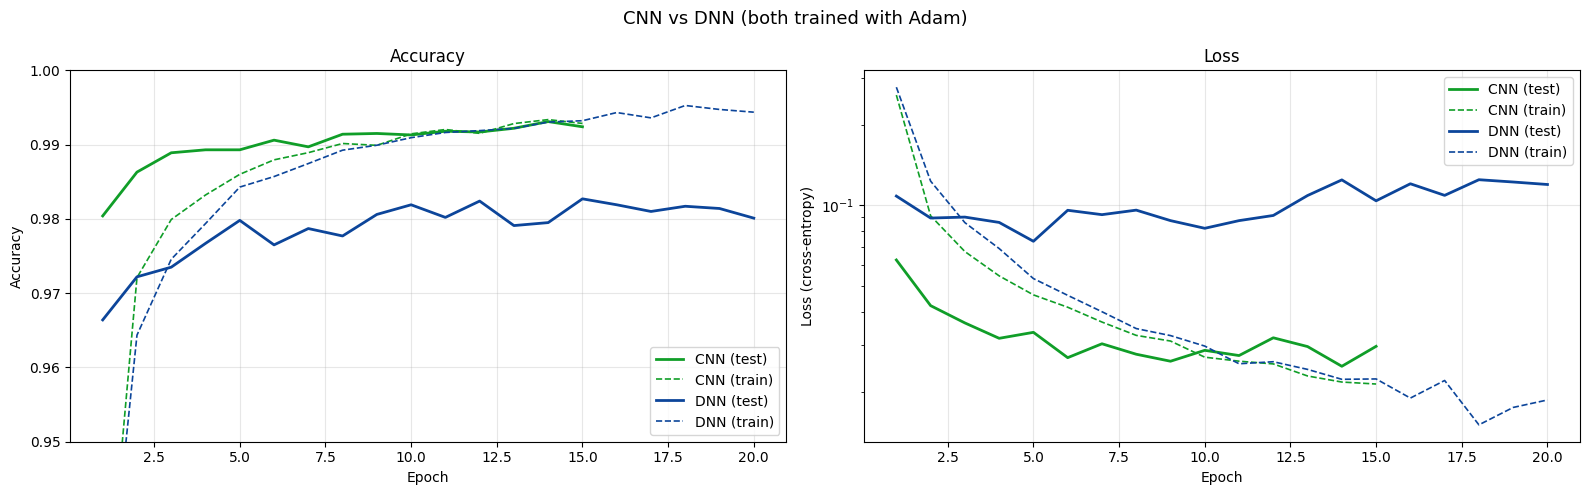

Wrong test images:  CNN 76,  DNN 199  (out of 10000)


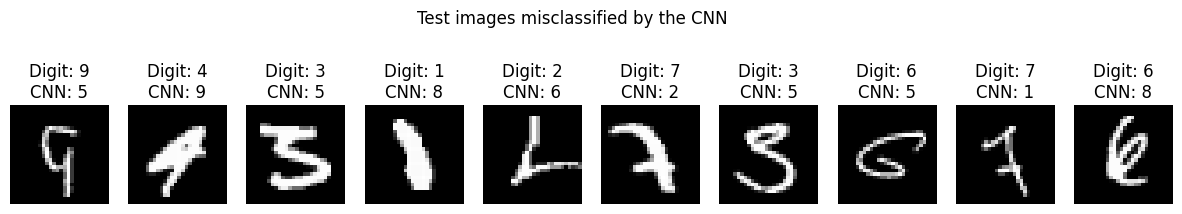

In [16]:
h_dnn, h_cnn = histories['adam'], history_CNN.history

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for key, ax in zip(['acc', 'loss'], axs):
    ax.plot(np.arange(1, len(h_cnn[key]) + 1), h_cnn['val_' + key], color=C_GREEN, lw=2, label='CNN (test)')
    ax.plot(np.arange(1, len(h_cnn[key]) + 1), h_cnn[key], color=C_GREEN, lw=1.2, ls='--', label='CNN (train)')
    ax.plot(np.arange(1, len(h_dnn[key]) + 1), h_dnn['val_' + key], color=C_BLUE, lw=2, label='DNN (test)')
    ax.plot(np.arange(1, len(h_dnn[key]) + 1), h_dnn[key], color=C_BLUE, lw=1.2, ls='--', label='DNN (train)')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)
axs[0].set(ylabel='Accuracy', title='Accuracy', ylim=(0.95, 1.0))
axs[1].set(ylabel='Loss (cross-entropy)', title='Loss', yscale='log')
fig.suptitle('CNN vs DNN (both trained with Adam)', fontsize=13)
plt.tight_layout()
plt.show()

# predicted digits
true_digit = np.argmax(Y_test, axis=1)
pred_CNN = np.argmax(model_CNN.predict(X_test, verbose=0), axis=1)
pred_DNN = np.argmax(model_DNN.predict(X_test.reshape(-1, img_rows*img_cols), verbose=0), axis=1)
print(f'Wrong test images:  CNN {np.sum(pred_CNN != true_digit)},  DNN {np.sum(pred_DNN != true_digit)}  (out of {len(true_digit)})')

# some images that the CNN gets wrong
wrong = np.where(pred_CNN != true_digit)[0][:10]
plt.figure(figsize=(15, 3))
for k, i in enumerate(wrong):
    plt.subplot(1, 10, k + 1)
    plt.imshow(X_test[i, :, :, 0], cmap='gray')
    plt.title(f'Digit: {true_digit[i]}\nCNN: {pred_CNN[i]}')
    plt.axis('off')
plt.suptitle('Test images misclassified by the CNN')
plt.show()

From the plots we can see that the CNN performs clearly better than the DNN. Its test accuracy is already about 98% after the first epoch and then stays around 99%, while the DNN remains around 98%. The number of misclassified test images confirms this: the CNN gets wrong 76 images out of 10000, against 199 for the DNN, so it makes less than half of the errors, even though it has about seven times fewer parameters. This is due to the structure of the network: the convolutional filters look for small local features, such as pieces of strokes and curves, and find them wherever they are in the image, while the DNN has to learn separately the role of each pixel.

The loss shows the same difference. The test loss of the CNN is much lower than that of the DNN: it reaches its minimum after a few epochs and then stays almost constant, with only small fluctuations. The test loss of the DNN, instead, grows during the training while its training loss keeps decreasing, which is a sign of overfitting. Finally, in the first epochs the training accuracy of the CNN is lower than the test accuracy. This is due to the dropout layer, which is active only during training, and to the fact that the training accuracy is averaged over each epoch.

### Exercise 12.3

Use the `gimp` application to create 10 pictures of your "handwritten" digits, import them in your jupyter-notebook and try to see if your CNN is able to recognize your handwritten digits.

For example, you can use the following code to import a picture of an handwritten digit
(Note: you should install Python Image Library (PIL/Pillow):

### <span style="color:green"> RESULTS: </span>

We drew the ten digits with GIMP, following the supplementary material. Each image was loaded in greyscale, rescaled to $[0,1]$ and inverted, so that the digit is white on a black background as in the MNIST images. Each digit was then classified by the CNN and by the DNN, and we show both the probability that each network assigns to its answer and the probabilities of all ten classes.

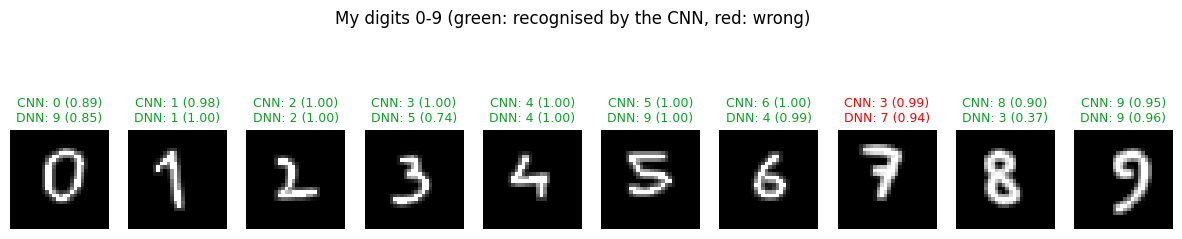

Correct digits:  CNN 9 / 10    DNN 5 / 10


In [25]:
from PIL import Image

def load_digit(filename):
    img = Image.open(filename).convert('L')                 # grey scale
    data = np.asarray(img, dtype='float32') / 255          # values in [0, 1]
    if data.mean() > 0.5:                                    # light background: invert
        data = 1 - data
    return data

my_digits = np.array([load_digit(f'./Pictures/m_{d}.png') for d in range(10)])

prob_CNN = model_CNN.predict(my_digits.reshape(10, 28, 28, 1), verbose=0)
prob_DNN = model_DNN.predict(my_digits.reshape(10, 28*28), verbose=0)

plt.figure(figsize=(15, 3.5))
for d in range(10):
    plt.subplot(1, 10, d + 1)
    plt.imshow(my_digits[d], cmap='gray')
    cnn, dnn = np.argmax(prob_CNN[d]), np.argmax(prob_DNN[d])
    plt.title(f'CNN: {cnn} ({prob_CNN[d].max():.2f})\nDNN: {dnn} ({prob_DNN[d].max():.2f})',
              color=C_GREEN if cnn == d else 'red', fontsize=9)
    plt.axis('off')
plt.suptitle('My digits 0-9 (green: recognised by the CNN, red: wrong)')
plt.show()

print('Correct digits:  CNN', np.sum(np.argmax(prob_CNN, axis=1) == np.arange(10)), '/ 10',
      '   DNN', np.sum(np.argmax(prob_DNN, axis=1) == np.arange(10)), '/ 10')

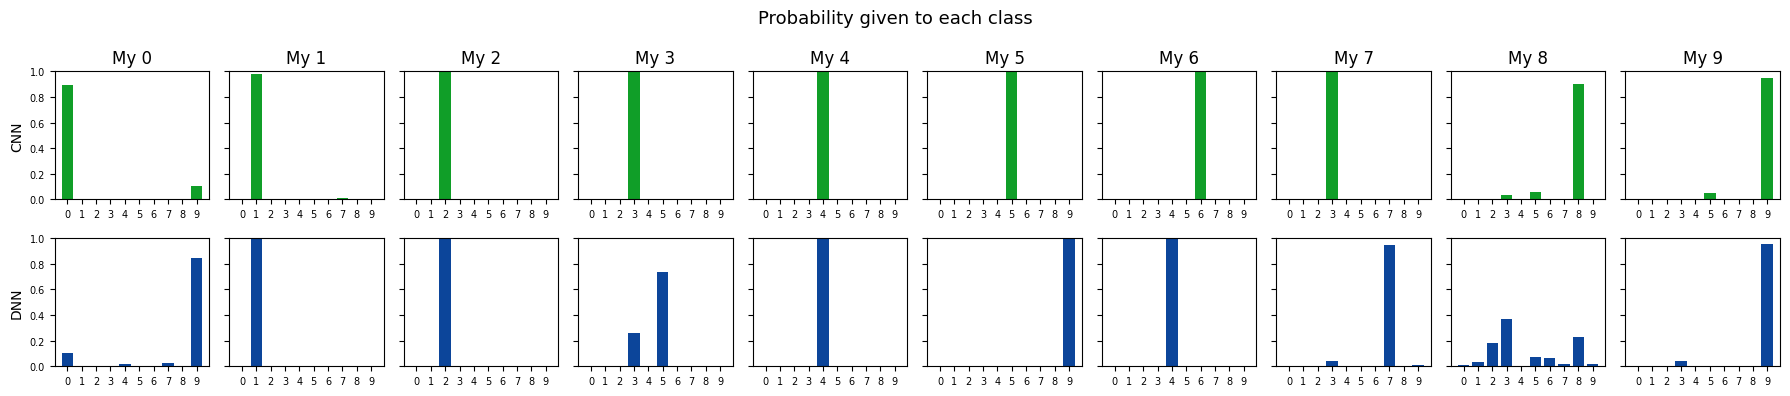

In [26]:
fig, axs = plt.subplots(2, 10, figsize=(18, 4), sharey=True)
for d in range(10):
    for row, (prob, col) in enumerate([(prob_CNN, C_GREEN), (prob_DNN, C_BLUE)]):
        ax = axs[row, d]
        ax.bar(range(10), prob[d], color=col)
        ax.set_xticks(range(10))
        ax.tick_params(labelsize=7)
        ax.set_ylim(0, 1)
    axs[0, d].set_title(f'My {d}')
axs[0, 0].set_ylabel('CNN')
axs[1, 0].set_ylabel('DNN')
fig.suptitle('Probability given to each class', fontsize=13)
plt.tight_layout()
plt.show()

With our set of digits the CNN recognises nine digits out of ten, while the DNN recognises only five. The bar plot shows the probability that each network gives to every class, so we can see not only the answer but also how sure the network is.

For most digits the CNN gives almost all the probability to the correct class. Only for the 0, the 8 and the 9 does a small part go to other digits. Its only error is the 7, which is classified as a 3 with a probability close to 1. Our 7 has a horizontal bar in the middle, while most of the sevens in MNIST are written without it, so the network has rarely seen this shape.

The DNN, instead, makes more errors, and most of them are made with high confidence. For example, the 5 and the 6 are classified as a 9 and a 4 with a probability close to 1. Only for the 3 and the 8 is the network uncertain: for the 3 the probability is split between 3 and 5, and for the 8 it is spread over several digits. This is consistent with the results on the MNIST test set. The DNN learns which pixels are usually white for each digit, so it is sensitive to small differences in the position and in the thickness of the stroke. The CNN filters, instead, look for local shapes wherever they are in the image.

These examples also show that the probability given by the softmax is not always a reliable measure of the uncertainty. Both networks can be wrong while being almost completely sure of their answer.

### <span style="color:green">Supplementary information 1: Use of `gimp` </span>

- from the Unix shell type: `gimp` and hit `Return`
- File -> new (chose: 28x28 pixels)
- rascale the image to 800%
- Use the **brush** with dimension 2px to draw your digit
- Color -> invert (to have black background)
- Export the image as a `.png` file

That's all!

### <span style="color:green">Supplementary information 2: Display trained filters in your CNN</span>

Print your NN layers:

In [18]:
layer_index=0
for layer in model_CNN.layers:
    print(layer_index, layer.name)
    layer_index+=1

0 conv2d_2
1 max_pooling2d_2
2 conv2d_3
3 max_pooling2d_3
4 flatten_1
5 dense_17
6 dropout_6
7 dense_18


Display your filters:

(5, 5, 1, 10)


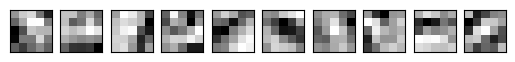

In [19]:
# layer_index should be the index of a convolutional layer
layer_index=0
# retrieve weights from the convolutional hidden layer
filters, biases = model_CNN.layers[layer_index].get_weights()
# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)
print(filters.shape)

# plot filters
n_filters, ix = filters.shape[3], 1
for i in range(n_filters):
    # get the filter
    f = filters[:, :, :, i]
    # specify subplot and turn of axis
    ax = plt.subplot(1,n_filters, ix)
    ax.set_xticks([])
    ax.set_yticks([])
    # plot filter channel in grayscale
    plt.imshow(f[:, :, 0], cmap='gray')
    ix += 1
# show the figure
plt.show()

### <span style="color:green">Supplementary information 3: Monitor layer outputs in your CNN</span>

In [ ]:
test_index = 0

from keras.models import Model
layer_outputs = [layer.output for layer in model_CNN.layers]
activation_model = Model(inputs=model_CNN.input, outputs=layer_outputs)
activations = activation_model.predict(X_test[test_index].reshape(1,28,28,1))
 
def display_activation(activations, col_size, row_size, layer_index): 
    activation = activations[layer_index]
    activation_index=0
    fig, ax = plt.subplots(row_size, col_size, figsize=(row_size*3,col_size*3))
    for row in range(0,row_size):
        for col in range(0,col_size):
            ax[row][col].imshow(activation[0, :, :, activation_index], cmap='gray')
            activation_index += 1

In [ ]:
%matplotlib inline
plt.imshow(X_test[test_index][:,:,0], cmap='gray')
# def display_activation(activations, col_size, row_size, layer number)
display_activation(activations, 4, 2, 0)
# col_size x row_size must be <= Number of filters for the convolutional layer